# **Анализ данных по проекту "Сайт для автосервиса"**
 Мухамадеев Айнур Алмазович

Начнем с **анализа рынка ремонта** ТС и оказания услуг Автосервисами:

Анализ
Минимальное значение 102.0 млрд. руб. в 2010 году
Максимальное значение 527.0 млрд. руб. в 2024 году
Прирост с 2010 по 2024 год составил 425.0 млрд. руб. (примерно в 5 раза)
Среднегодовой темп прироста составляет 12%


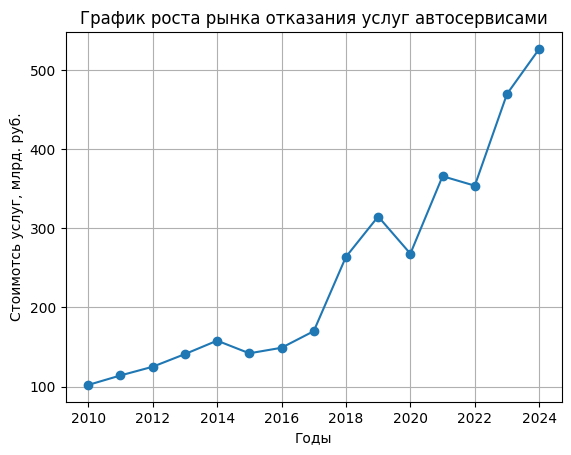

In [ ]:
from ast import Index
import numpy as np
import csv
import matplotlib.pyplot as plt

fname = "/content/rynok_avtoservisa.csv"
with open(fname, mode='r', encoding="utf-8-sig") as file:
    readfile = csv.reader(file, delimiter=";")
    head_file = next(readfile)
    rows = list(readfile)

years = np.array([int(row[0]) for row in rows])
volume = np.array([float(row[1]) for row in rows])

print("Анализ")
print(f"Минимальное значение {np.min(volume)} млрд. руб. в {years[np.argmin(volume)]} году")
print(f"Максимальное значение {np.max(volume)} млрд. руб. в {years[np.argmax(volume)]} году")
print(f"Прирост с 2010 по 2024 год составил {np.max(volume) - np.min(volume)} млрд. руб. (примерно в {int(np.max(volume) / np.min(volume))} раза)")
print(f"Среднегодовой темп прироста составляет {int(((volume[-1] / volume[0]) ** (1 / (len(years) - 1)) - 1) * 100)}%")


plt.plot(years, volume, marker='o')
plt.title("График роста рынка отказания услуг автосервисами")
plt.xlabel("Годы")
plt.ylabel("Стоимотсь услуг, млрд. руб.")
plt.grid()
plt.show()


Выоды по рынку:

Рынок оказания услуг автосервисами в период с 2010 по 2024 год стремительно растет (несмортя на небольшие провалы в 2015, 2020, 2022 годах), средний прирост в 12% это доказывает.

Рынок быстро востановился после кризиса 2015 года, после Пандемии, и после начала военных дествий. Это показывает высокую устойчивость сферы.




**Теперь расмотрим средний возраст автомобилей на рынке Россиян**

Анализ
Самый «молодой»: сегмент легковых автомобилей (15.5 лет)
Самый «старый»: сегмент грузовых автомобилей (20.9 лет)
Средний возраст по всем представленным категориям: 17.8 лет


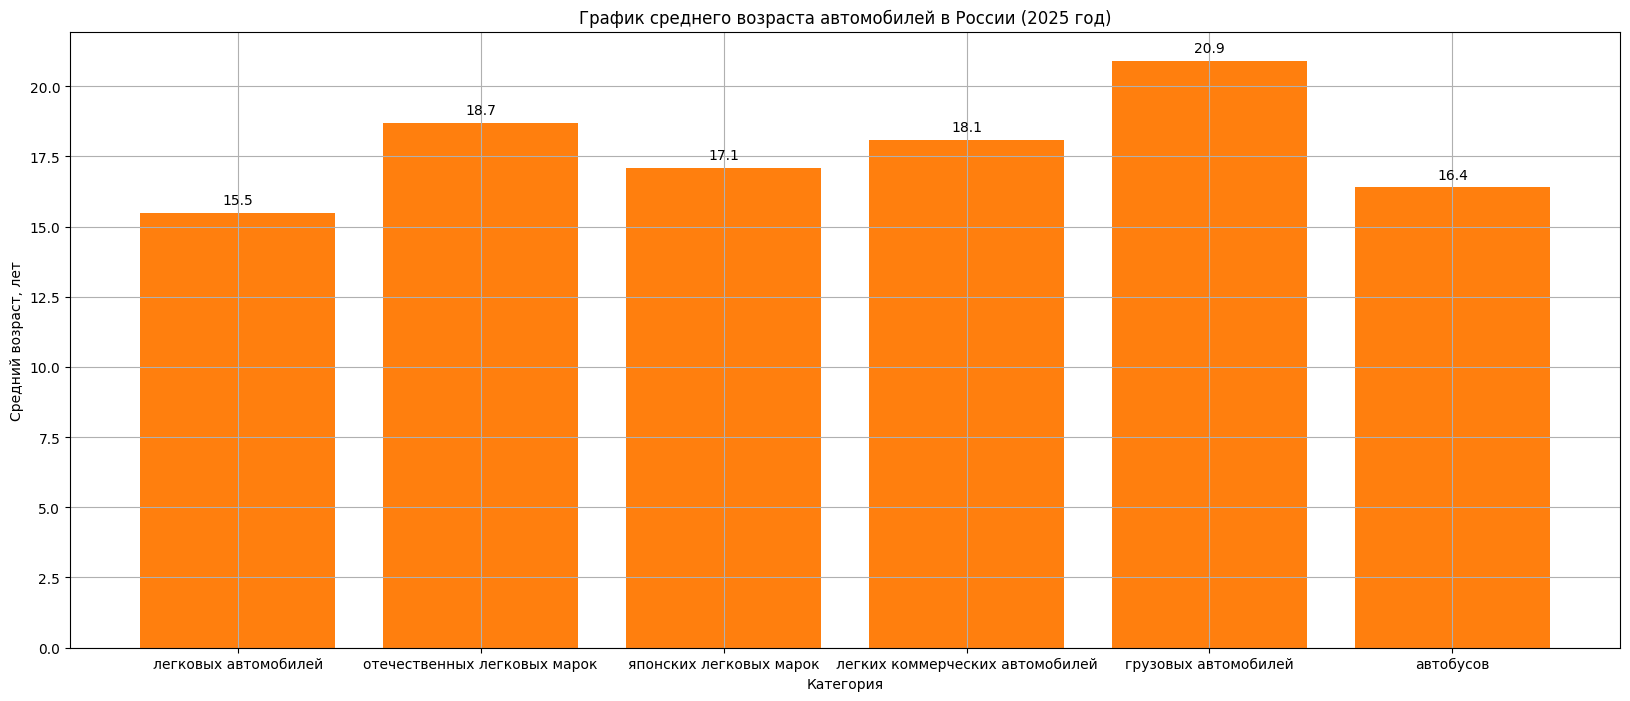

In [ ]:
fname = "/content/vozrast_avto.csv"
with open(fname, mode='r', encoding="utf-8-sig") as file:
    readfile = csv.reader(file, delimiter=";")
    head_file = next(readfile)
    rows = list(readfile)

years = np.array([int(row[0]) for row in rows])
labels = np.array([str(row[1].replace('Средний_возраст_', '').replace("_", " ")) for row in rows])
ages = np.array([float(row[2]) for row in rows])


print("Анализ")
print(f"Самый «молодой»: сегмент {labels[ages.argmin()]} ({ages.min()} лет)")
print(f"Самый «старый»: сегмент {labels[ages.argmax()]} ({ages.max()} лет)")
print(f"Средний возраст по всем представленным категориям: {round(np.mean(ages), 1)} лет")

plt.figure(figsize=(20, 8))
plt.bar(labels, ages)
for bar in plt.bar(labels, ages):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f'{bar.get_height()}', ha='center')

plt.title("График среднего возраста автомобилей в России (2025 год)")
plt.xlabel("Категория")
plt.ylabel("Средний возраст, лет")
plt.grid()
plt.show()

Выводы:

Анализ данных показывает прямую зависимость между критическим старением автопарка в России (средний возраст — от 15,5 до 20,9 лет) и пятикратным ростом объёма рынка автосервисных услуг (до 527 млрд руб. к 2024 году). В ближайшие годы число обращений в СТО продолжит расти, так как владельцы вынуждены дольше эксплуатировать возрастную технику. В этих условиях традиционный ручной учёт перестаёт справляться с потоком заявок, поэтому внедрение цифровых инструментов становится для автосервисов необходимым условием сохранения скорости и качества обслуживания.

Именно владельцы отечественного легкового и грузового транспорта будут основными пользователями сайта онлайн-записи (массовый спрос + потребность в быстром ремонте без простоя)


Далее посмотрим "**автопарк**" России

Анализ: Легковые автомобили
Минимум: 34.35 млн шт. (2010 г.)
Максимум: 50.61 млн шт. (2022 г.)
Средний прирост между периодами: 10.71%

Анализ: Грузовые автомобили
Минимум: 5.41 млн шт. (2010 г.)
Максимум: 6.67 млн шт. (2022 г.)
Средний прирост между периодами: 5.52%

Анализ: Автобусы
Минимум: 138.0 тыс. шт. (2022 г.)
Максимум: 174.0 тыс. шт. (2015 г.)
Средний прирост между периодами: -3.02%


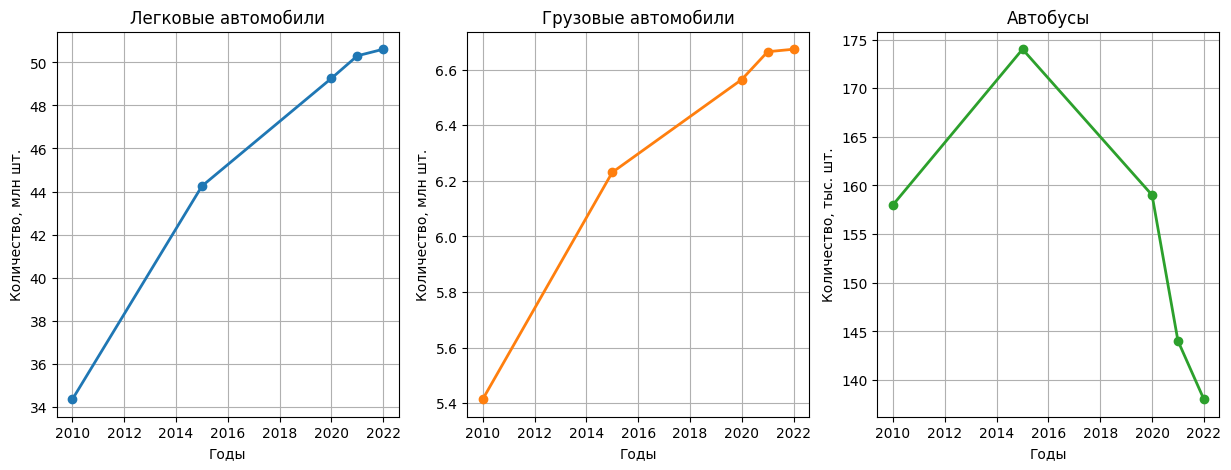

In [ ]:
fname = "/content/avtopark.csv"

with open(fname, mode='r', encoding="utf-8-sig") as file:
    readfile = csv.reader(file, delimiter=";")
    head_file = next(readfile)
    rows = list(readfile)

years_all = np.array([int(row[0]) for row in rows])
types = np.array([str(row[1]) for row in rows])
values_all = np.array([float(row[2]) for row in rows])

years = [y for y in np.unique(years_all)]
cars = values_all[types == 'Легковые_автомобили'] / 1000
trucks = values_all[types == 'Грузовые_автомобили'] / 1000
buses = values_all[types == 'Автобусы']

print("Анализ: Легковые автомобили")
print(f"Минимум: {round(cars.min(), 2)} млн шт. ({years_str[cars.argmin()]} г.)")
print(f"Максимум: {round(cars.max(), 2)} млн шт. ({years_str[cars.argmax()]} г.)")
print(f"Средний прирост между периодами: {round(np.mean((np.diff(cars) / cars[:-1]) * 100), 2)}%\n")

print("Анализ: Грузовые автомобили")
print(f"Минимум: {round(trucks.min(), 2)} млн шт. ({years_str[trucks.argmin()]} г.)")
print(f"Максимум: {round(trucks.max(), 2)} млн шт. ({years_str[trucks.argmax()]} г.)")
print(f"Средний прирост между периодами: {round(np.mean((np.diff(trucks) / trucks[:-1]) * 100), 2)}%\n")

print("Анализ: Автобусы")
print(f"Минимум: {round(buses.min(), 1)} тыс. шт. ({years_str[buses.argmin()]} г.)")
print(f"Максимум: {round(buses.max(), 1)} тыс. шт. ({years_str[buses.argmax()]} г.)")
print(f"Средний прирост между периодами: {round(np.mean((np.diff(buses) / buses[:-1]) * 100), 2)}%")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].plot(years_str, cars, marker='o', color='#1f77b4', linewidth=2)
axes[0].set_title("Легковые автомобили")
axes[0].set_xlabel("Годы")
axes[0].set_ylabel("Количество, млн шт.")
axes[0].grid()

axes[1].plot(years_str, trucks, marker='o', color='#ff7f0e', linewidth=2)
axes[1].set_title("Грузовые автомобили")
axes[1].set_xlabel("Годы")
axes[1].set_ylabel("Количество, млн шт.")
axes[1].grid()

axes[2].plot(years_str, buses, marker='o', color='#2ca02c', linewidth=2)
axes[2].set_title("Автобусы")
axes[2].set_xlabel("Годы")
axes[2].set_ylabel("Количество, тыс. шт.")
axes[2].grid()

plt.show()


Выводы:

Легковые автомобили демонстрируют самый уверенный рост: парк увеличился с 34,35 до 50,61 млн шт., а средний прирост между периодами составил +10,71%. Это самый массовый сегмент, который продолжает расширяться на всём протяжении периода.

Грузовые автомобили также показывают стабильную положительную динамику: их количество выросло с 5,41 до 6,67 млн шт. (средний прирост +5,52% между периодами), закрепившись на максимальных значениях к 2022 году.

Автобусы имеют обратный тренд: после пика в 2015 году (174 тыс. шт.) их численность ежегодно снижалась и упала до минимума в 138 тыс. шт. в 2022 году (среднее изменение составило -3,02%). Но в то же время автобусы не являются частыми посетителями комерческих автосервисов, а так же отрицательный рост количества автобусов компенсируется значительным ростом легковых автомобилей

А теперь прелейдем к анализу **способа записи в крупных автосервисах**


Анализ
Самый популярный способ: Через сайт (31.0%)
Самый редкий способ: Через приложение (7.0%)
Суммарная доля цифровых каналов: 64.0%


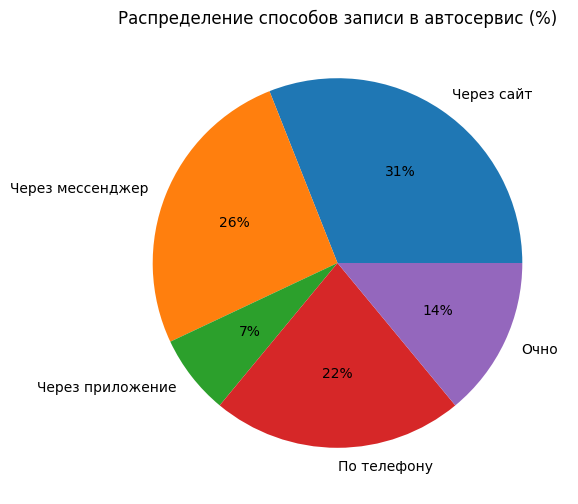

In [ ]:
fname = "/content/zapis.csv"

with open(fname, mode='r', encoding="utf-8-sig") as file:
    readfile = csv.reader(file, delimiter=";")
    head_file = next(readfile)
    rows = list(readfile)

methods = np.array([row[0].replace('_', ' ') for row in rows])
shares = np.array([float(row[1]) for row in rows])

print("Анализ")
print(f"Самый популярный способ: {methods[shares.argmax()]} ({shares.max()}%)")
print(f"Самый редкий способ: {methods[shares.argmin()]} ({shares.min()}%)")
print(f"Суммарная доля цифровых каналов: {shares[0] + shares[1] + shares[2]}%")


plt.figure(figsize=(8, 6))
plt.pie(
    shares,
    labels=methods,
    autopct='%1.0f%%',
)

plt.title('Распределение способов записи в автосервисах (%)')
plt.show()


Выводы:

Запись через сайт занимает первое место среди всех каналов взаимодействия с клиентами, опережая традиционные телефонные звонки (22%) почти в полтора раза.

Доля записи через отдельное приложение составляет всего 7%, тогда как через сайт — 31%. Скорее всего клиентам неудобно скачивать отдельное приложение ради редких визитов на ТО или ремонт, поэтому веб-сайт является самым доступным и оправданным решением для автосервиса.


Наконец, посмотрим **динамику роста выручки после внедрения онлайн записи** в некоторых компаниях.

Анализ
Лидер роста: Мотор-Сервис (+31%)
Худший: АвтоЛидер (-3%)
Средний рост: 14.3%


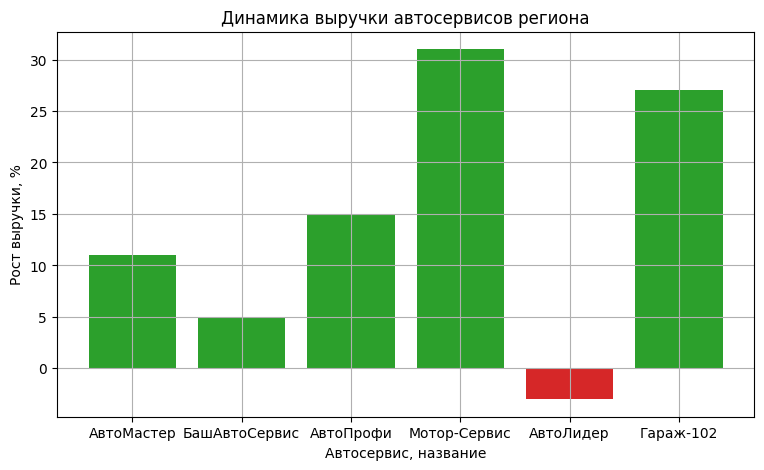

Красный столбец -- отрицательное значение
Зеленый столбец -- положительное значение


In [115]:
fname = "/content/rost.csv"

with open(fname, mode='r', encoding="utf-8-sig") as file:
    reader = csv.reader(file, delimiter=";")
    headers = next(reader)
    rows = [r for r in reader if r]

names = np.array([r[0] for r in rows])
growth = np.array([float(r[1]) for r in rows])

print("Анализ")
print(f"Лидер роста: {names[growth.argmax()]} ({growth.max():+.0f}%)")
print(f"Худший: {names[growth.argmin()]} ({growth.min():+.0f}%)")
print(f"Средний рост: {round(np.mean(growth), 1)}%")

plt.figure(figsize=(9, 5))
colors = ['#2ca02c' if val >= 0 else '#d62728' for val in growth]
bars = plt.bar(names, growth, color=colors)

plt.grid()
plt.title('Динамика выручки автосервисов региона')
plt.ylabel('Рост выручки, %')
plt.xlabel('Автосервис, название')
plt.show()

print("Красный столбец -- отрицательное значение")
print("Зеленый столбец -- положительное значение")


Выводы:

Диаграмма наглядно показывает, что после внедрения онлайн записи выручка автосервисов растут в среднем на 14,3%. Внедрение сайта онлайн-записи позволяет автосервису исключить потерю клиентов на этапе звонка менеджеру и приблизиться к показателям лидеров рынка.

# Общий вывод:

Проведённый анализ подтверждает, что разработка сайта онлайн-записи для автосервиса является актуальным, востребованным и экономически обоснованным проектом.
Непрерывный рост численности и среднего возраста легковых и грузовых автомобилей (более 57,2 млн единиц) обеспечивает автосервисам постоянный приток клиентов. В этих условиях традиционная ручная запись по телефону через менеджера перестаёт справляться с нагрузкой и приводит к потере заказчиков. Внедрение веб-сайта закрывает запрос самой крупной категории пользователей (31%), автоматизирует процесс приёма заявок, снижает нагрузку на персонал и создаёт конкурентное преимущество, позволяющее автосервису увеличить выручку и закрепиться среди лидеров рынка.